# Connectivity between offshore wind farms in the German EEZ

Example of [OceanTracker](https://oceantracker.github.io/oceantracker/) on the SCHISM
GermanBight hindcast (`/hpcfreenas/hindcast/Europe/GermanBight`, 1–31 January 2020) 
to examine the larval connectivity between windfarms.

**Workflow**

1. `fetch_windfarms.py` downloads the wind farm outlines (EMODnet) and the German EEZ (Marine
   Regions), and turns them into non-overlapping polygons.
2. `run_connectivity.py` runs two OceanTracker simulations with the same physics and releases:
   - **stats**: 1000 particles per farm every hour until 7 days before the run ends, `max_age` = 14 days,
     with an on-the-fly settlement statistic
   - **tracks**: the same release with 2 particles per pulse, tracks written every 6 h, used for the maps.
3. This notebook visualizes the results.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import patheffects
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
from matplotlib.patches import FancyArrowPatch
from matplotlib.tri import Triangulation
from pyproj import Transformer

from oceantracker.read_output.python import load_output_files as lof

%matplotlib inline

QUICK = False        # True: use the outputs of `python run_connectivity.py --quick`
RUN_MODEL = False    # True: (re)run the simulations first (the stats run takes ~3 h on 64 cores)

STATS_DIR = Path('output/windfarm_connectivity' + ('_quick' if QUICK else ''))
TRACKS_DIR = Path('output/windfarm_tracks' + ('_quick' if QUICK else ''))
TABLE_DIR = STATS_DIR / 'tables'
DATA_DIR = Path('data')
hour, day = 3600., 86400.

loading oceantracker read files


prelim: 		Starting package set up


In [2]:
if not (DATA_DIR / 'windfarms_polygons_utm32n.json').exists():
    import fetch_windfarms
    fetch_windfarms.main()

if RUN_MODEL or not (TRACKS_DIR / 'caseInfo.json').exists():
    from run_connectivity import build_tracks_model
    build_tracks_model(quick=QUICK).run()

if RUN_MODEL or not (STATS_DIR / 'caseInfo.json').exists():
    from run_connectivity import build_stats_model
    build_stats_model(quick=QUICK).run()

### Load the output

In [3]:
stats_case = str(STATS_DIR / 'caseInfo.json')
tracks_case = str(TRACKS_DIR / 'caseInfo.json')
case = lof.read_case_info_file(stats_case)
age_stats = lof.load_stats_data(stats_case, name='windfarm_connectivity')
run_info = case['run_info']    # release schedule and particle forecast, per model time step
tracks = lof.load_track_data(tracks_case)
grid = lof.load_grid(stats_case)

names = [str(n) for n in age_stats['release_group_names']]
farms = gpd.read_file(DATA_DIR / 'windfarms_lonlat.geojson').set_index('short_name').loc[names]
farms_utm = farms.to_crs(32632)
eez = gpd.read_file(DATA_DIR / 'eez_germany_lonlat.geojson')

# farms are numbered west -> east on all maps and matrix axes
order = np.argsort(farms.geometry.representative_point().x.values)
num = {names[n]: k + 1 for k, n in enumerate(order)}
labels = [f'{num[names[n]]:>2}  {names[n]}' for n in order]

stats_params = case['working_params']['class_roles']['particle_statistics']['windfarm_connectivity']
release_params = next(iter(case['working_params']['class_roles']['release_groups'].values()))
run_start = pd.to_datetime(case['run_info']['start_time'], unit='s')
run_end = pd.to_datetime(case['run_info']['end_time'], unit='s')
count_start = pd.to_datetime(stats_params['start'], unit='s')
age_edges = np.asarray(age_stats['age_bin_edges'], float)          # seconds
max_age = release_params['max_age']

print(f'{len(names)} farms, run {run_start} to {run_end}, counting from {count_start}')
print(f'settlement age bins [d]: {np.round(age_edges / day, 2)}')

Merging rectangular track files
	 Reading rectangular track file "tracks_rectangular_000.nc"


26 farms, run 2020-01-01 01:00:00 to 2020-01-31 00:00:00, counting from 2020-01-15 01:00:00
settlement age bins [d]: [ 7.  8.  9. 10. 11. 12. 13. 14.]


### Plotting helpers

In [4]:
to_lonlat = Transformer.from_crs(32632, 4326, always_xy=True).transform
lon_nodes, lat_nodes = to_lonlat(grid['x'][:, 0], grid['x'][:, 1])
tri = Triangulation(lon_nodes, lat_nodes, grid['triangles'])
label_xy = farms.geometry.representative_point()

# single-hue sequential ramps for magnitudes; fixed categorical colours for fates
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
BLUES_W = LinearSegmentedColormap.from_list('blues_w', ['#ffffff', '#9ec5f4', '#3987e5', '#1c5cab', '#0d366b'])
OWN, OTHER, NONE = '#2a78d6', '#eb6834', '#c9c7c1'
FARM, FARM_EDGE, HIGHLIGHT = '#d9534f', '#8b1e1a', '#d9534f'
LAND, WATER, INK, MUTED, EMPTY = '#e6e4df', '#ffffff', '#222222', '#6b6b6b', '#f4f4f2'
CNORM = LogNorm(1e-4, 1)   # fixed colour scale for all connectivity plots
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.titlelocation': 'left'})


def draw_base(ax, mesh=False):
    """Water on land, German EEZ dashed, optionally the model mesh."""
    ax.set_facecolor(LAND)
    ax.tripcolor(tri, np.zeros(len(tri.triangles)), cmap=LinearSegmentedColormap.from_list('w', [WATER, WATER]),
                 shading='flat', rasterized=True)
    if mesh:
        ax.triplot(tri, lw=0.3, color='#9a9a9a')
    eez.boundary.plot(ax=ax, color=MUTED, lw=0.8, ls='--')
    ax.set_aspect(1 / np.cos(np.deg2rad(54.5)))
    ax.set_xlabel('Longitude [°E]')
    ax.set_ylabel('Latitude [°N]')


def number_labels(ax, size=6.5):
    for name, p in label_xy.items():
        ax.annotate(str(num[name]), (p.x, p.y), ha='center', va='center', fontsize=size, color=INK, zorder=6,
                    path_effects=[patheffects.withStroke(linewidth=2, foreground='white')])


def zoom(ax, gdf, dx=0.3, dy=0.15):
    b = gdf.total_bounds
    ax.set_xlim(b[0] - dx, b[2] + dx)
    ax.set_ylim(b[1] - dy, b[3] + dy)


def date_axis(ax):
    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))


def colorbar(fig, mappable, ax, label, **kwargs):
    cb = fig.colorbar(mappable, ax=ax, label=label, **kwargs)
    cb.outline.set_visible(False)
    return cb


def matrix(ax, m, norm=CNORM, tick_labels=None):
    """Source x destination matrix in west -> east order, zeros grey."""
    m = m[np.ix_(order, order)]
    im = ax.imshow(np.ma.masked_where(~(m > 0), m), cmap=BLUES, norm=norm, interpolation='nearest')
    ax.set_facecolor(EMPTY)
    ticks = np.arange(len(order))
    tl = tick_labels or [str(k + 1) for k in ticks]
    ax.set_xticks(ticks, tl, rotation=90 if tick_labels else 0, fontsize=7 if tick_labels else 5.5)
    ax.set_yticks(ticks, tl, fontsize=7 if tick_labels else 5.5)
    for sp in ax.spines.values():
        sp.set_visible(False)
    return im

## 1. Wind farm polygons

The study uses 26 North Sea farms inside the German EEZ that are operating, under construction or
approved. Each farm is used both as a **release polygon** and as a **counting polygon**.
OceanTracker's polygon statistics need single, non-overlapping rings, so some EMODnet geometries
were cleaned up; the README lists the details.

In [5]:
tab = farms.iloc[order][['status', 'year', 'n_turbines', 'power_mw', 'area_km2']].copy()
tab.insert(0, 'no.', np.arange(1, len(order) + 1))
tab['year'] = pd.to_numeric(tab['year'], errors='coerce').astype('Int64')
tab['n_turbines'] = pd.to_numeric(tab['n_turbines'], errors='coerce').astype('Int64')
tab.index.name = 'farm'
tab.round({'power_mw': 0, 'area_km2': 1})

,no.,status,year,n_turbines,power_mw,area_km2
farm,,,,,,
Deutsche Bucht,1,Production,2019,31,252.0,17.1
Veja Mate,2,Production,2017,67,402.0,50.7
Bard Offshore 1,3,Production,<NA>,80,400.0,56.7
EnBW He Dreiht,4,Approved,<NA>,64,960.0,62.6
Borkum Riffgrund 3,5,Construction,<NA>,<NA>,240.0,75.4
Albatros,6,Production,2020,16,118.0,10.5
EnBW Hohe See,7,Production,2019,71,497.0,40.4
Global Tech I,8,Production,2015,80,400.0,39.8
Trianel Borkum,9,Production,2015,72,403.0,53.3


The hindcast files don't record a coordinate reference system. Assume UTM32N (EPSG:32632),
Near the farms the mesh edges are about 0.3–3 km long, so many farms cover only a few model cells (right).

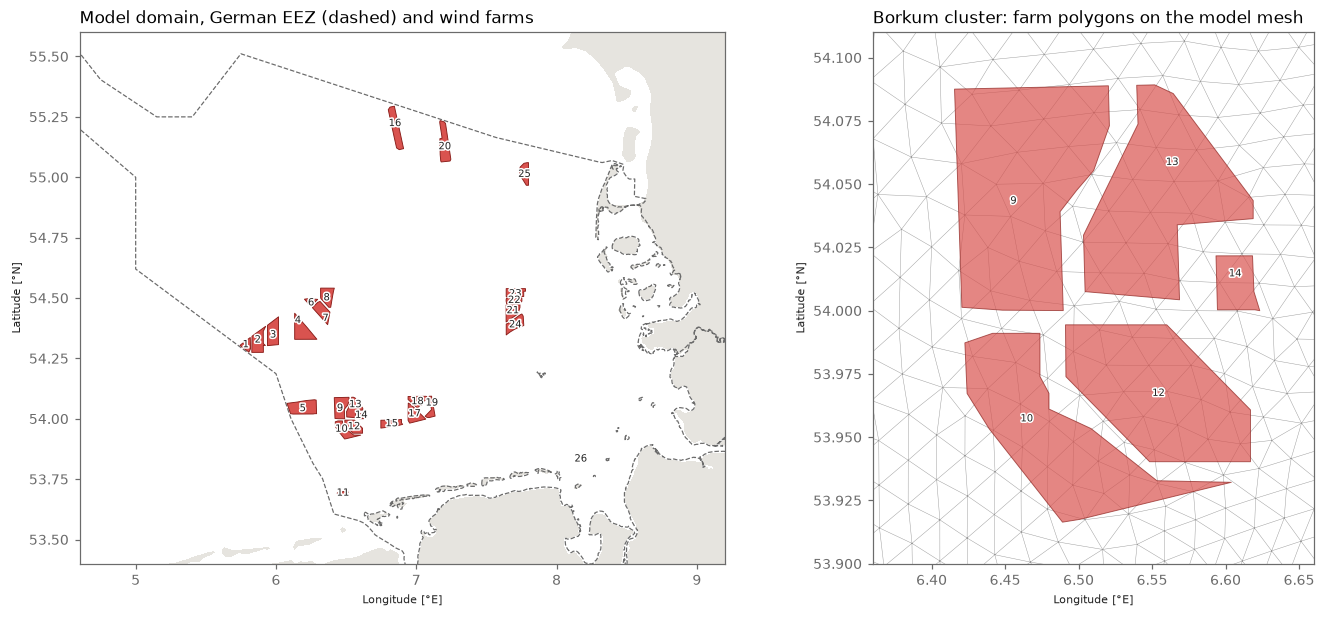

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
views = [((4.6, 9.2), (53.4, 55.6), 'Model domain, German EEZ (dashed) and wind farms'),
         ((6.36, 6.66), (53.9, 54.11), 'Borkum cluster: farm polygons on the model mesh')]
for ax, (xl, yl, title) in zip(axs, views):
    draw_base(ax, mesh=ax is axs[1])
    farms.plot(ax=ax, facecolor=FARM, edgecolor=FARM_EDGE, lw=0.6, alpha=0.7 if ax is axs[1] else 1., zorder=4)
    number_labels(ax)
    ax.set_xlim(xl)
    ax.set_ylim(yl)
    ax.set_title(title)

## 2. Model set-up and particle budget

| item | value |
|---|---|
| hydrodynamics | SCHISM v5 split output, hourly, 3D velocities, 2020-01-01 01:00 – 01-31 00:00 |
| releases | one `PolygonRelease` per farm, 1000 particles every hour until 7 days before the run ends (24 Jan 00:00 for this hindcast; later larvae can't reach 7 days, the start of the settlement window), released 10 cm above the seabed (`release_at_bottom=True`, `release_offset_from_surface_or_bottom=0.1`), standing in for e.g. bivalve larvae; passive, no swimming or sinking |
| particle lifetime | `max_age` = 14 days |
| physics | `time_step` 300 s, horizontal random walk `A_H` = 1 m² s⁻¹, vertical random walk from SCHISM diffusivity (`use_A_Z_profile`) |
| settlement statistics | age-based polygon stats with the release polygons as counting polygons; only particles on the seabed (`status_list=['on_bottom']`), checked at every time step (`update_interval` = `time_step` = 300 s) and each time counted with a 10 % chance (`counting_probability=0.1`), so every time step on the seabed is one 10 % chance to settle; counting starts after 14 days (2020-01-15); ages 7–14 days in daily bins; `max_count_per_particle=1`, `kill_when_max_counted=True`, so a settled particle is removed from the simulation |


**Expected number of particles.** 
26 farms × 1000 particles/h = 26,000 particles/h. 
Particles are kept up to and including age 14 d,
which is 337 hourly pulses, so the plateau is at about 26,000 × 337 ≈ **8.76 million**.
Releases stop on 7 days before the model end as those particles won't reach the competency window anymore.
With 552 hourly releases, about 14.4 million particles are released in total.

## 3. Particle tracks

These maps use the companion **tracks** run (2 particles per farm per hour, positions every 6 h),
showing a random sample of 3000 tracks. Each dot is a particle's last position, coloured by its age
at that point. Over 14 days particles spread tens of km from their farm.

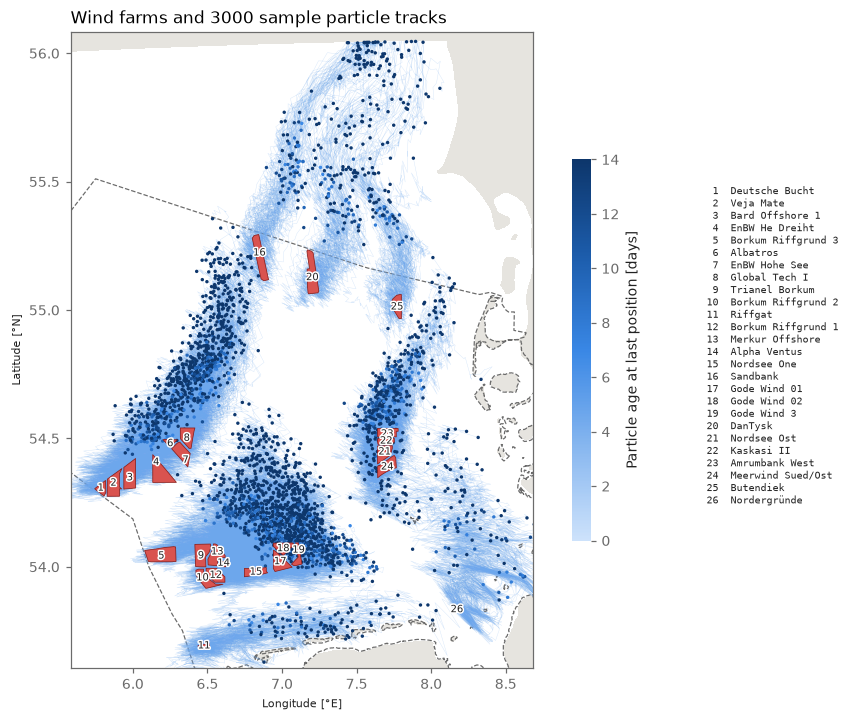

In [8]:
x = tracks['x'][:, :, :2]
age_tr = tracks['age'] / day
ok_tr = tracks['status'] >= 0          # alive (stationary = 0, moving = 10 etc.)

rng = np.random.default_rng(0)
sel = rng.choice(x.shape[1], size=min(3000, x.shape[1]), replace=False)
lon_t, lat_t = to_lonlat(x[:, sel, 0], x[:, sel, 1])
ok = ok_tr[:, sel] & np.isfinite(lon_t)
lon_t[~ok], lat_t[~ok] = np.nan, np.nan
last = ok.shape[0] - 1 - np.argmax(ok[::-1], axis=0)
cols, has = np.arange(len(sel)), ok.any(axis=0)

fig, ax = plt.subplots(figsize=(9, 7.5))
draw_base(ax)
ax.plot(lon_t, lat_t, color='#6da7ec', lw=0.25, alpha=0.3, zorder=2)
sc = ax.scatter(lon_t[last, cols][has], lat_t[last, cols][has], s=1.5, c=age_tr[last, sel][has], cmap=BLUES,
                vmin=0, vmax=max_age / day, zorder=3)
farms.plot(ax=ax, facecolor=FARM, edgecolor=FARM_EDGE, lw=0.5, zorder=4)
number_labels(ax)
ax.set_xlim(np.nanpercentile(lon_t, 0.2) - 0.1, np.nanpercentile(lon_t, 99.8) + 0.1)
ax.set_ylim(np.nanpercentile(lat_t, 0.2) - 0.05, np.nanpercentile(lat_t, 99.8) + 0.05)
colorbar(fig, sc, ax, 'Particle age at last position [days]', shrink=0.6)
key = '\n'.join(labels)
fig.text(0.92, 0.5, key, fontsize=6.5, family='monospace', va='center', ha='left', color=INK)
ax.set_title(f'Wind farms and {len(sel)} sample particle tracks');

### How a particle cloud spreads with age

These panels show all tracks-run particles from one farm, at a given age, pooled over all release
times. The age-based statistic counts the 7–14-day part of this cloud wherever it overlaps a farm.

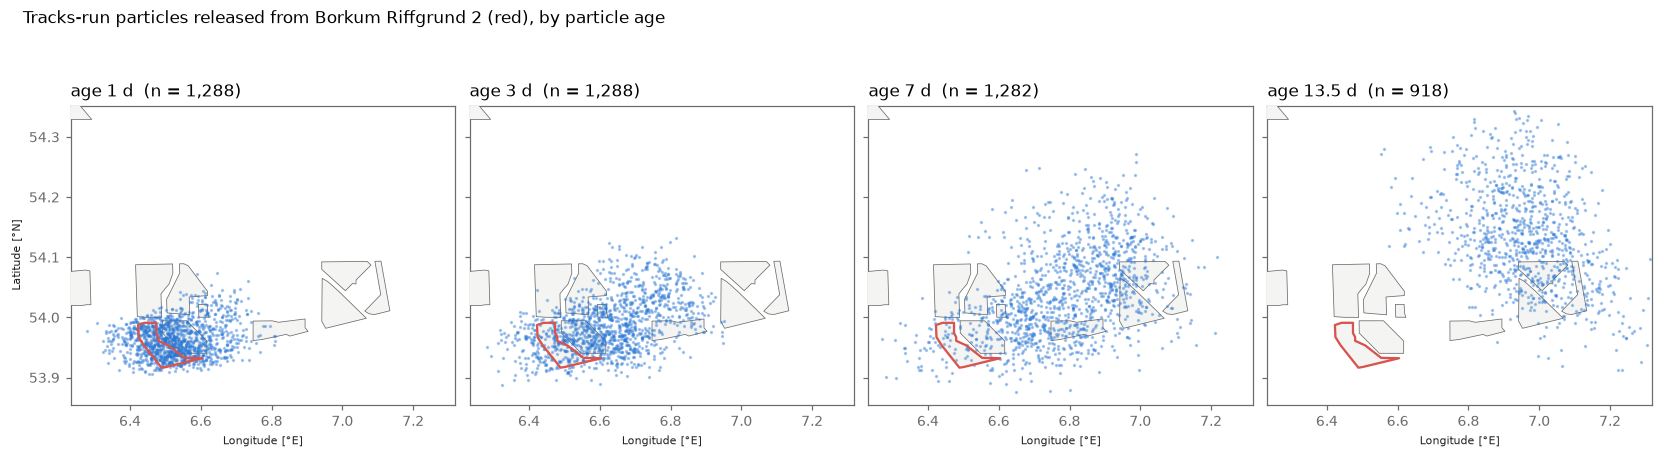

In [9]:
SOURCE = 'Borkum Riffgrund 2'
ages_d = [1, 3, 7, 13.5] if not QUICK else [0.25, 0.5, 1, 1.75]

g = names.index(SOURCE)
in_group = tracks['IDrelease_group'] == g
lon_g, lat_g = to_lonlat(x[:, in_group, 0], x[:, in_group, 1])
age_g, ok_g = age_tr[:, in_group], ok_tr[:, in_group]
panels = [(a, (np.abs(age_g - a) <= 0.125) & ok_g) for a in ages_d]   # +/- 3 h around each age

fig, axs = plt.subplots(1, len(panels), figsize=(15, 4.3), sharex=True, sharey=True, constrained_layout=True)
for ax, (a, s) in zip(axs, panels):
    draw_base(ax)
    farms.plot(ax=ax, facecolor=EMPTY, edgecolor=MUTED, lw=0.5, zorder=3)
    ax.scatter(lon_g[s], lat_g[s], s=1.5, color=OWN, alpha=0.35, zorder=4, rasterized=True)
    farms.loc[[SOURCE]].plot(ax=ax, facecolor='none', edgecolor=HIGHLIGHT, lw=1.5, zorder=5)
    ax.set_title(f'age {a:g} d  (n = {s.sum():,})')
    if ax is not axs[0]:
        ax.set_ylabel('')
s_all = np.any([s for _, s in panels], axis=0)
sb = farms.loc[[SOURCE]].total_bounds
ax.set_xlim(min(np.nanpercentile(lon_g[s_all], 0.5), sb[0]) - 0.1, max(np.nanpercentile(lon_g[s_all], 99.5), sb[2]) + 0.1)
ax.set_ylim(min(np.nanpercentile(lat_g[s_all], 0.5), sb[1]) - 0.05, max(np.nanpercentile(lat_g[s_all], 99.5), sb[3]) + 0.05)
fig.suptitle(f'Tracks-run particles released from {SOURCE} (red), by particle age', x=0.01, ha='left');

## 4. Settlement connectivity: what is counted

From `count_start` onwards, every time step (300 s) finds the particles that are **on the seabed,
inside a farm and aged 7–14 days**. Each of them settles with a **10 % chance** at that step, so a
particle that stays on the bed for several steps gets one chance per step. A particle
settles **once**, in that farm (which may be its own farm), and is then **removed** from the
simulation (`kill_when_max_counted=True`), so it can't settle again and no other statistic counts it.
`count[age, source, destination]` is therefore a count of unique particles, binned by
**age at settlement**.

A particle is "on the seabed" (status `on_bottom`) when a time step leaves it at the bed. OceanTracker
updates the statistics before resuspension lifts such particles off again, so the statistics see
them even though the screen output always reports `Bottom:0`.

### Fate of each farm's eligible particles

For each source farm, the eligible particles fall into three groups: those that settle in **their
own farm**, those that settle in **another farm**, and those that never settle while aged 7–14 days
(**no farm**): they never touch the seabed inside a farm in that age window, or are not picked by the
10 % chance when they do.

eligible particles per farm: 551,000–551,000 (551 of 552 release times)
median over farms: own 0.04, another farm 0.05, no farm 0.91


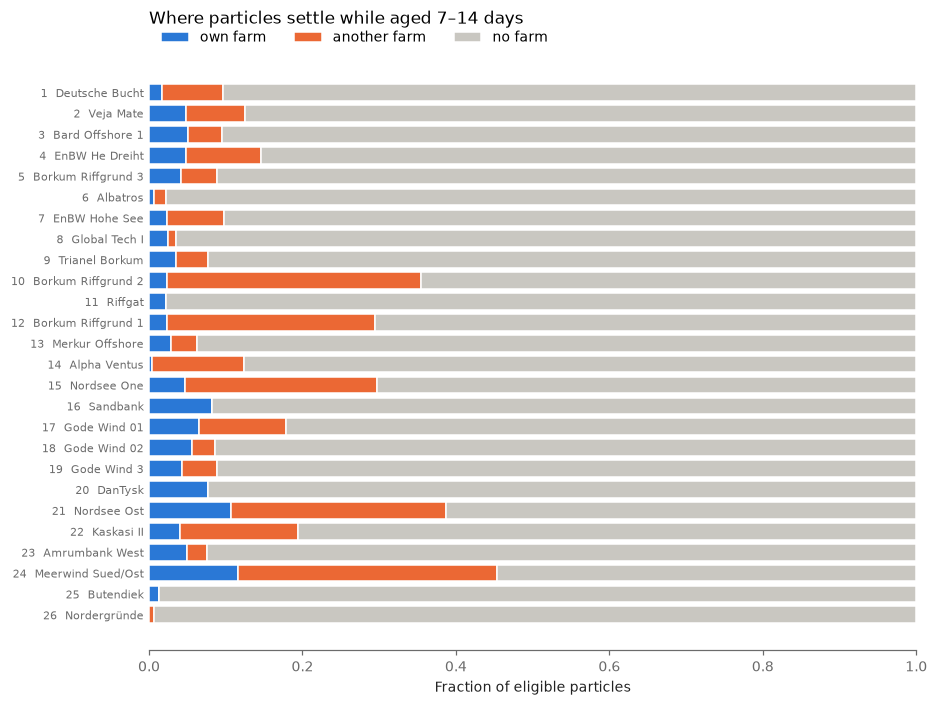

In [10]:
# denominator: particles from each farm that are 7-14 days old at one or more updates while counting
# runs, from the releases actually recorded per time step (so it follows the release window)
a0, a1 = age_edges[0], age_edges[-1]
cs, re_ = count_start.value / 1e9, run_end.value / 1e9
t_sec = np.asarray(run_info['times'], float)
released_step = np.diff(np.asarray(run_info['cumulative_number_released'], float), prepend=0)   # all farms
per_farm = np.asarray(age_stats['number_released_each_release_group'], float)
n_rel = released_step[:, None] * (per_farm / per_farm.sum())[None, :]                           # (time, farm)
t_sec, n_rel = t_sec[released_step > 0], n_rel[released_step > 0]                                # release times only
updates = np.arange(cs, re_ + 1, stats_params['update_interval'])
age_at_updates = updates[None, :] - t_sec[:, None]
eligible = ((age_at_updates >= a0) & (age_at_updates < a1)).any(axis=1)              # per release time
N_elig = (n_rel * eligible[:, None]).sum(axis=0)                                       # per source farm
print(f'eligible particles per farm: {N_elig.min():,.0f}–{N_elig.max():,.0f} ({eligible.sum()} of {eligible.size} release times)')

count = np.asarray(np.ma.filled(np.ma.asarray(age_stats['count'], dtype=float), 0.))   # (age, source, dest)
C_age = count / N_elig[None, :, None]          # settlement probability by age bin
C = count.sum(axis=0) / N_elig[:, None]        # settlement probability over all ages
own = np.diag(C)
other = C.sum(axis=1) - own
none = 1 - own - other
assert np.all(none >= -1e-9), 'more settlements than eligible particles'

fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(order))
left = np.zeros(len(order))
for vals, color, lab in [(own, OWN, 'own farm'), (other, OTHER, 'another farm'), (none, NONE, 'no farm')]:
    v = vals[order]
    ax.barh(y, v, left=left, color=color, edgecolor='white', lw=1, height=0.8, label=lab)
    left += v
ax.set_yticks(y, labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel('Fraction of eligible particles')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.legend(frameon=False, ncol=3, loc='lower left', bbox_to_anchor=(0, 1.0))
ax.set_title('Where particles settle while aged 7–14 days', pad=22);

print(f'median over farms: own {np.median(own):.2f}, another farm {np.median(other):.2f}, '
      f'no farm {np.median(none):.2f}')

## 5. Connectivity matrices

`C[source, destination]` is the probability that an eligible particle from *source* settles in
*destination* while aged 7–14 days. The diagonal is self-recruitment, and grey means zero.

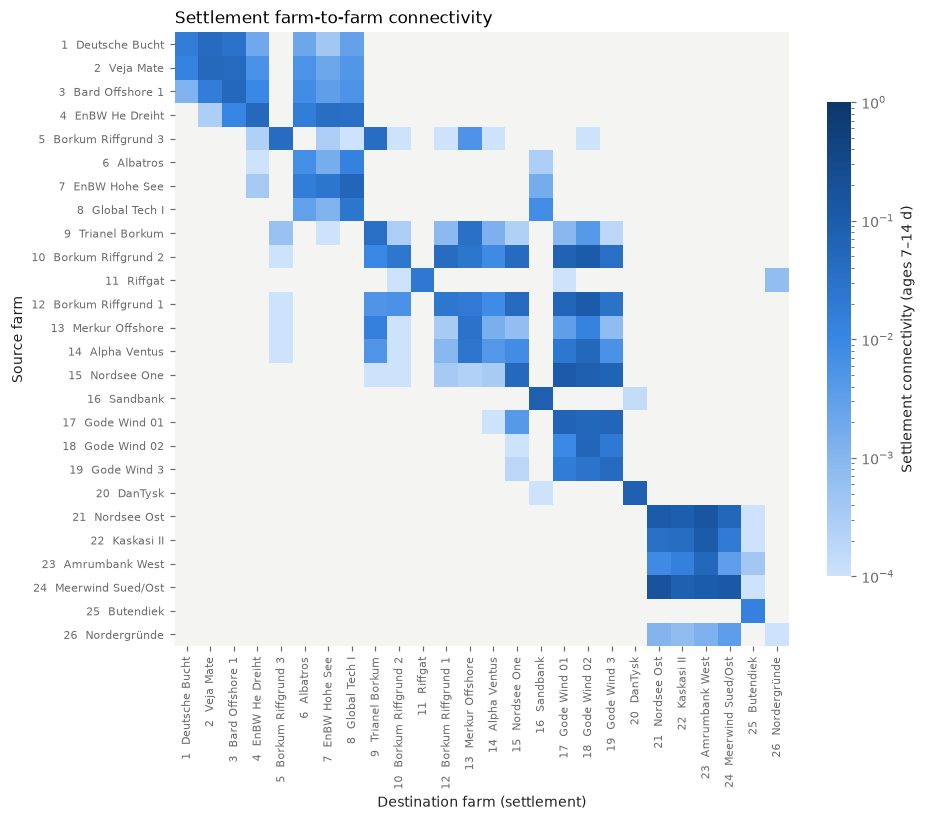

In [11]:
fig, ax = plt.subplots(figsize=(9, 8))
im = matrix(ax, C, tick_labels=labels)
ax.set_xlabel('Destination farm (settlement)')
ax.set_ylabel('Source farm')
colorbar(fig, im, ax, 'Settlement connectivity (ages 7–14 d)', shrink=0.7)
ax.set_title('Settlement farm-to-farm connectivity');

The strongest links between different farms, with the gap between farm edges:

In [12]:
geom = farms_utm.geometry.values
dist_km = np.array([[a.distance(b) / 1e3 for b in geom] for a in geom])
S, D = np.meshgrid(np.arange(len(names)), np.arange(len(names)), indexing='ij')
links = pd.DataFrame(dict(source=np.array(names)[S.ravel()], destination=np.array(names)[D.ravel()],
                          connectivity=C.ravel(), edge_distance_km=dist_km.ravel()))
links = links[(S != D).ravel()].reset_index(drop=True)

links.sort_values('connectivity', ascending=False).head(15).round({'connectivity': 4, 'edge_distance_km': 1})

,source,destination,connectivity,edge_distance_km
445,Meerwind Sued/Ost,Nordsee Ost,0.1658,0.9
527,Nordsee Ost,Amrumbank West,0.1439,3.8
138,Borkum Riffgrund 2,Gode Wind 02,0.1018,27.6
113,Borkum Riffgrund 1,Gode Wind 02,0.1008,25.1
402,Kaskasi II,Amrumbank West,0.1005,0.7
513,Nordsee One,Gode Wind 01,0.1005,3.1
427,Meerwind Sued/Ost,Amrumbank West,0.0942,8.1
541,Nordsee Ost,Kaskasi II,0.0836,0.7
514,Nordsee One,Gode Wind 02,0.0829,8.9
441,Meerwind Sued/Ost,Kaskasi II,0.0768,5.0


## 6. Connectivity versus distance

Distance is measured between farm edges, not centroids, because many neighbouring farms share a
boundary.

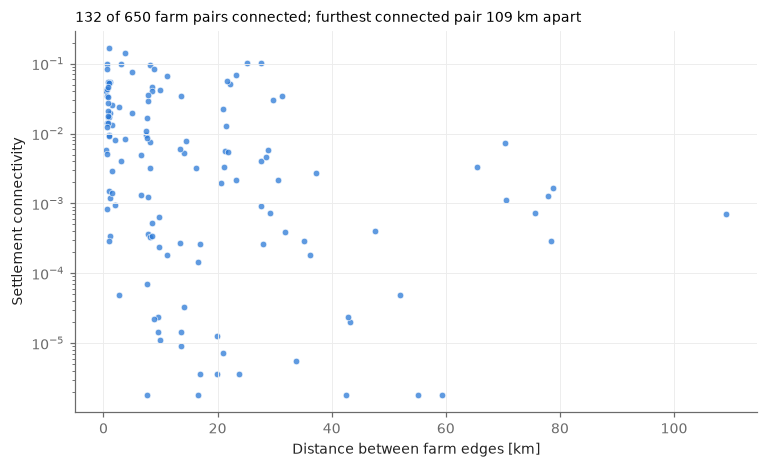

In [13]:
pos = links.connectivity > 0
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(links.edge_distance_km[pos], links.connectivity[pos], s=18, color=OWN, alpha=0.75,
           edgecolor='white', lw=0.5)
ax.set_yscale('log')
ax.set_xlabel('Distance between farm edges [km]')
ax.set_ylabel('Settlement connectivity')
ax.grid(color='#ececec', lw=0.6)
ax.spines[['top', 'right']].set_visible(False)
ax.set_title(f'{pos.sum()} of {len(links)} farm pairs connected; furthest connected pair '
             f'{links.edge_distance_km[pos].max():.0f} km apart', fontsize=9);

## 7. Connectivity network

Arrows show links with settlement connectivity of at least 1 %. Each arrow curves to the left of
its direction, so A→B and B→A can be told apart. Width and shade both scale with connectivity.

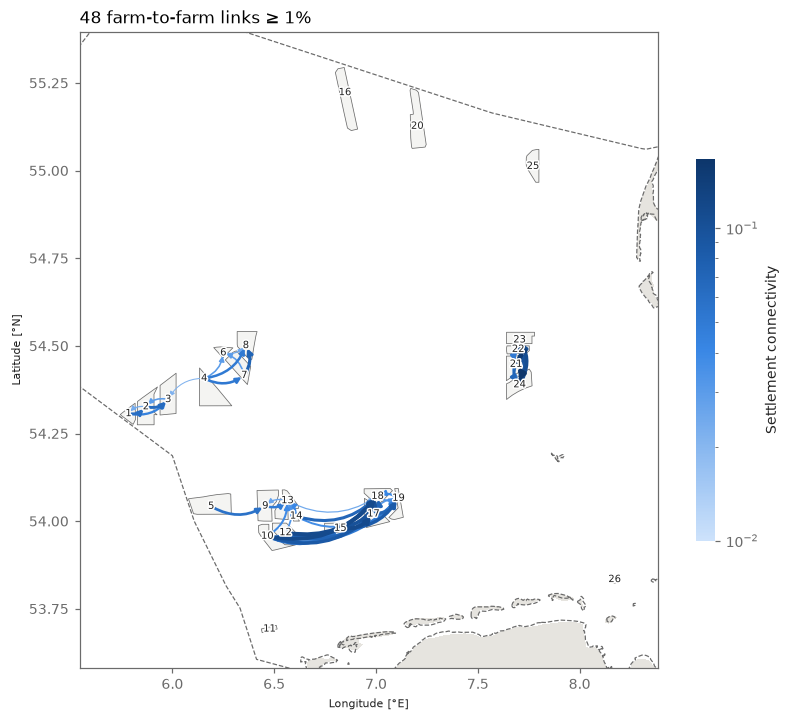

In [14]:
THRESH = 1e-2
strong = links[links.connectivity >= THRESH].sort_values('connectivity')
norm = LogNorm(THRESH, max(strong.connectivity.max(), 2 * THRESH))

fig, ax = plt.subplots(figsize=(9, 7.5))
draw_base(ax)
farms.plot(ax=ax, facecolor=EMPTY, edgecolor=MUTED, lw=0.5, zorder=3)
for r in strong.itertuples():
    p0, p1 = label_xy[r.source], label_xy[r.destination]
    f = norm(r.connectivity)
    ax.add_patch(FancyArrowPatch((p0.x, p0.y), (p1.x, p1.y), connectionstyle='arc3,rad=0.3',
                                 arrowstyle='-|>', mutation_scale=7, lw=0.6 + 2.4 * f,
                                 color=BLUES(0.25 + 0.75 * f), zorder=5))
number_labels(ax)
zoom(ax, farms, 0.2, 0.1)
colorbar(fig, ScalarMappable(norm=norm, cmap=BLUES), ax, 'Settlement connectivity', shrink=0.6)
ax.set_title(f'{len(strong)} farm-to-farm links ≥ {THRESH:.0%}');

## 8. Connectivity from individual farms

Each map shows where eligible particles from one farm (red outline) settle in another
farm. The colour scale is fixed (10⁻⁴–1), so the maps can be compared with each other and with the
matrices. You can add any farm name from the table in section 1 to `SOURCES`.

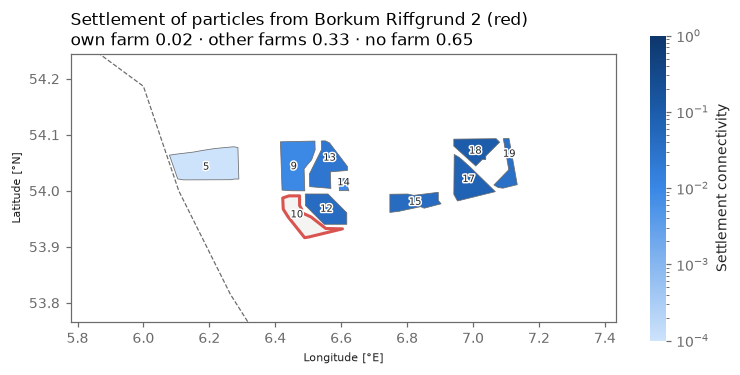

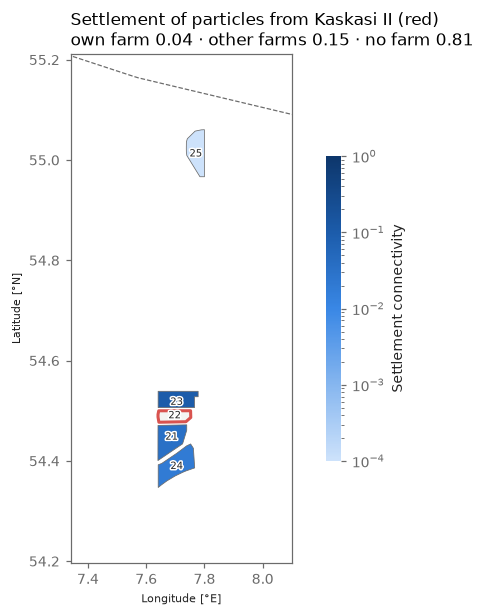

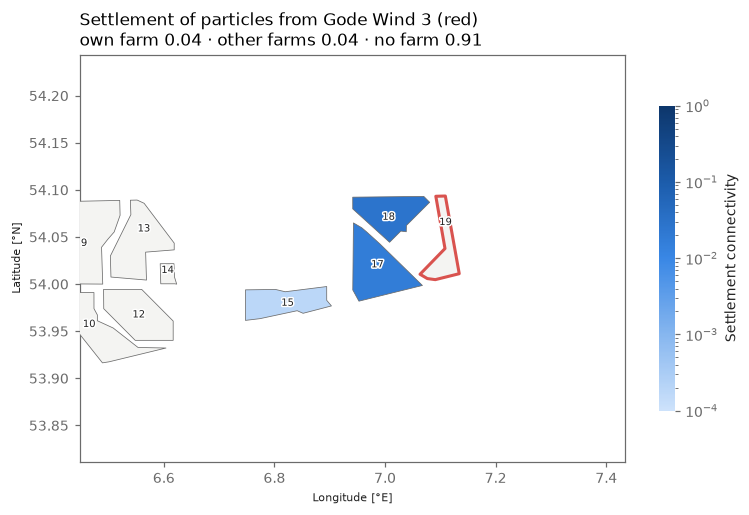

In [15]:
def source_map(source):
    s = names.index(source)
    vals = pd.Series(C[s], index=names)
    vals[source] = np.nan
    pos = vals > 0
    fig, ax = plt.subplots(figsize=(8, 6))
    draw_base(ax)
    farms[~pos].plot(ax=ax, facecolor=EMPTY, edgecolor=MUTED, lw=0.5, zorder=3)
    if pos.any():
        farms[pos].assign(c=vals[pos]).plot(ax=ax, column='c', cmap=BLUES, norm=CNORM, edgecolor=MUTED,
                                            lw=0.5, zorder=3)
    farms.loc[[source]].plot(ax=ax, facecolor='none', edgecolor=HIGHLIGHT, lw=2, zorder=4)
    number_labels(ax)
    zoom(ax, farms[pos | (farms.index == source)])
    colorbar(fig, ScalarMappable(norm=CNORM, cmap=BLUES), ax, 'Settlement connectivity', shrink=0.6)
    ax.set_title(f'Settlement of particles from {source} (red)\n'
                 f'own farm {C[s, s]:.2f} · other farms {other[s]:.2f} · no farm {none[s]:.2f}')


SOURCES = ['Borkum Riffgrund 2', 'Kaskasi II', 'Gode Wind 3']
for s in SOURCES:
    source_map(s)